# LAB 2 — ĐẶC TRƯNG TIẾNG NÓI VÀ NHẬN DẠNG BẰNG DTW
**CSE457 – Xử lý Âm thanh và Tiếng nói | Trường Đại học Thủy Lợi**  
**MSSV:** 2351260680 | **Họ tên:** Nguyễn Hồng Phúc

---
**Pipeline tổng quan:**
```
Dataset WAV  →  [B] Energy/ZCR  →  [C] Endpoint Detection
             →  [D] MFCC        →  [E] DTW (tự cài đặt)
             →  [F] Recognizer  →  [G] Đánh giá + Thí nghiệm
```

## 📦 Bước 0 — Import thư viện & Cấu hình toàn cục

In [1]:
import os, glob
import numpy as np
import librosa
import librosa.display
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy.signal import lfilter
from scipy.fft import dct
from sklearn.metrics import confusion_matrix, accuracy_score, ConfusionMatrixDisplay
import pandas as pd
from IPython.display import Audio, display

# ── Tham số toàn cục (giữ nhất quán giữa train & test) ──────────────────────
FS          = 16000          # Sample rate
FRAME_MS    = 25             # Frame length (ms)
HOP_MS      = 10             # Hop size (ms)
WIN         = int(FS * FRAME_MS / 1000)   # 400 samples
HOP         = int(FS * HOP_MS   / 1000)   # 160 samples
N_FFT       = 512
N_MELS      = 24
N_MFCC      = 13
ALPHA       = 0.97           # Pre-emphasis
TOP_DB      = 35             # Ngưỡng endpoint detection
MARGIN_MS   = 50             # Padding margin sau trim (ms)

DATASET_WAV = 'dataset_wav'
LABELS      = ['khong', 'mot', 'hai', 'ba', 'bon']
LABEL_NAMES = {'khong': 'không', 'mot': 'một', 'hai': 'hai', 'ba': 'ba', 'bon': 'bốn'}
N_PER_LABEL = 5

os.makedirs('figures', exist_ok=True)
print('✅ Import thành công!')
print(f'   WIN={WIN} samples ({FRAME_MS}ms) | HOP={HOP} samples ({HOP_MS}ms)')
print(f'   N_MELS={N_MELS} | N_MFCC={N_MFCC} | N_FFT={N_FFT}')


✅ Import thành công!
   WIN=400 samples (25ms) | HOP=160 samples (10ms)
   N_MELS=24 | N_MFCC=13 | N_FFT=512


---
## 📂 Bước A — Tải dữ liệu
Dữ liệu đã được convert sang WAV 16kHz Mono ở notebook trước.
- **3 file đầu** (index 00, 01, 02) → **Template training**
- **2 file còn lại** (index 03, 04) → **Test set**

In [2]:
def load_audio(path):
    """Đọc file WAV, resample về FS, chuẩn hóa biên độ."""
    y, sr = librosa.load(path, sr=FS, mono=True)
    y = y / (np.max(np.abs(y)) + 1e-9)
    return y

# Liệt kê tất cả file WAV
all_files  = {}   # {label: [path0, path1, ..., path4]}
train_files = {}  # {label: [path0, path1, path2]}
test_files  = {}  # {label: [path3, path4]}

for label in LABELS:
    files = sorted(glob.glob(os.path.join(DATASET_WAV, label, '*.wav')))
    all_files[label]   = files
    train_files[label] = files[:3]
    test_files[label]  = files[3:]
    print(f'  {label}: {len(files)} file | train={len(files[:3])} | test={len(files[3:])}')

print(f'\n✅ Tổng: {sum(len(v) for v in all_files.values())} file')
print(f'   Train: {sum(len(v) for v in train_files.values())} file')
print(f'   Test : {sum(len(v) for v in test_files.values())} file')


  khong: 5 file | train=3 | test=2
  mot: 5 file | train=3 | test=2
  hai: 5 file | train=3 | test=2
  ba: 5 file | train=3 | test=2
  bon: 5 file | train=3 | test=2

✅ Tổng: 25 file
   Train: 15 file
   Test : 10 file


---
## 📊 Bước B — Đặc trưng miền thời gian (Short-time Energy, RMS, ZCR)

Chia tín hiệu thành các **frame 25ms** (hop 10ms), áp cửa sổ **Hamming**, rồi tính:
- **Short-time Energy (STE):** $E_r = \sum_n x_r^2[n]$
- **RMS:** $\text{RMS}_r = \sqrt{\frac{1}{L}\sum_n x_r^2[n]}$
- **Log-energy (dB):** $E_{dB} = 10 \log_{10}(E_r + \varepsilon)$
- **Zero-Crossing Rate (ZCR):** $Z_r = \frac{1}{2L}\sum_n |\text{sgn}(x_r[n]) - \text{sgn}(x_r[n-1])|$

In [3]:
def compute_ste_zcr(y, win=WIN, hop=HOP):
    """
    Tính Short-time Energy, RMS, Log-Energy và ZCR theo từng frame.
    Returns:
        ste   : Short-time energy
        rms   : Root Mean Square energy
        log_e : Log-energy (dB)
        zcr   : Zero-Crossing Rate
    """
    n_frames = 1 + (len(y) - win) // hop
    ste   = np.zeros(n_frames)
    rms   = np.zeros(n_frames)
    zcr   = np.zeros(n_frames)

    window = np.hamming(win)

    for i in range(n_frames):
        frame = y[i*hop : i*hop + win] * window
        ste[i]  = np.sum(frame ** 2)
        rms[i]  = np.sqrt(np.mean(frame ** 2))
        zcr[i]  = np.sum(np.abs(np.sign(frame[1:]) - np.sign(frame[:-1]))) / (2 * win)

    log_e = 10 * np.log10(ste + 1e-10)
    return ste, rms, log_e, zcr


def frame_times(n_frames, hop=HOP, sr=FS):
    """Trả về mảng thời gian trung tâm của từng frame."""
    return np.arange(n_frames) * hop / sr


print('✅ Hàm compute_ste_zcr() đã sẵn sàng')


✅ Hàm compute_ste_zcr() đã sẵn sàng


### B.1 — Vẽ Waveform + Energy + ZCR cho ít nhất 3 từ

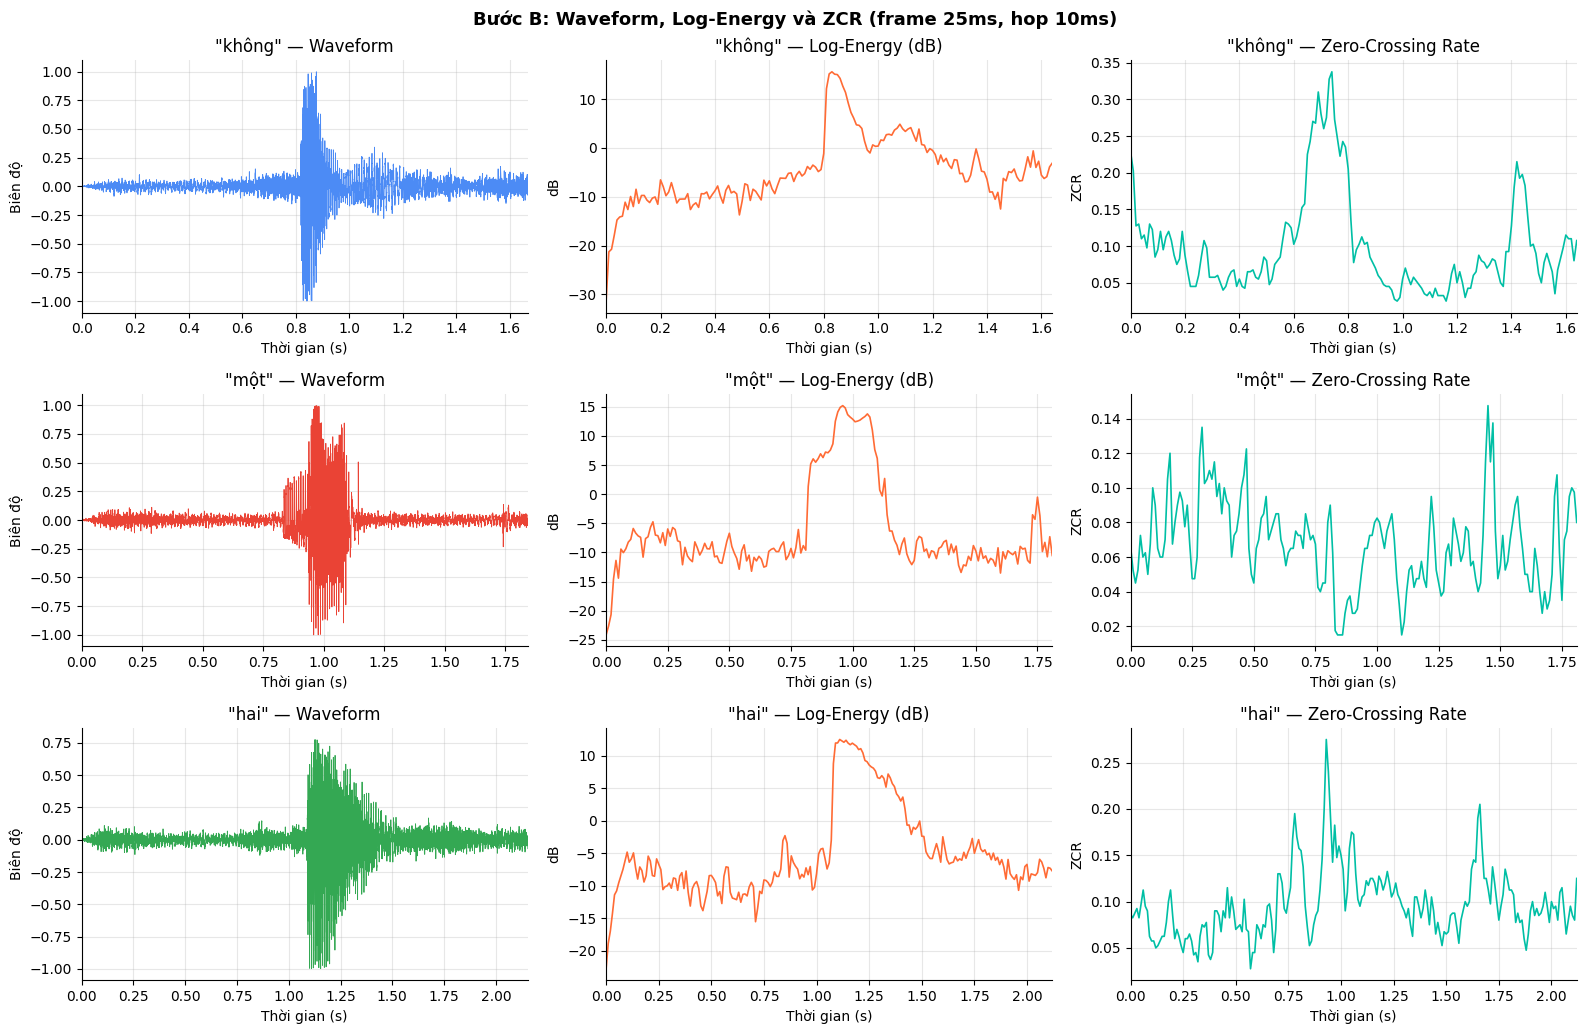

💾 Lưu: figures/B_energy_zcr.png


In [4]:
COLORS = ['#4C8BF5', '#EA4335', '#34A853', '#FBBC05', '#AB47BC']
DEMO_LABELS = LABELS[:3]   # Vẽ 3 từ đầu

fig, axes = plt.subplots(len(DEMO_LABELS), 3, figsize=(16, 3.5 * len(DEMO_LABELS)))
fig.suptitle('Bước B: Waveform, Log-Energy và ZCR (frame 25ms, hop 10ms)',
             fontsize=13, fontweight='bold')

for row, label in enumerate(DEMO_LABELS):
    y = load_audio(all_files[label][0])
    ste, rms, log_e, zcr = compute_ste_zcr(y)
    t_sig  = np.arange(len(y)) / FS
    t_frame = frame_times(len(ste))
    color = COLORS[row]

    # Waveform
    ax0 = axes[row, 0]
    ax0.plot(t_sig, y, color=color, lw=0.6)
    ax0.set_title(f'"{LABEL_NAMES[label]}" — Waveform')
    ax0.set_xlabel('Thời gian (s)'); ax0.set_ylabel('Biên độ')
    ax0.set_xlim(0, t_sig[-1]); ax0.grid(alpha=0.3)

    # Log-Energy
    ax1 = axes[row, 1]
    ax1.plot(t_frame, log_e, color='#FF6B35', lw=1.2)
    ax1.set_title(f'"{LABEL_NAMES[label]}" — Log-Energy (dB)')
    ax1.set_xlabel('Thời gian (s)'); ax1.set_ylabel('dB')
    ax1.set_xlim(0, t_frame[-1]); ax1.grid(alpha=0.3)

    # ZCR
    ax2 = axes[row, 2]
    ax2.plot(t_frame, zcr, color='#00BFA5', lw=1.2)
    ax2.set_title(f'"{LABEL_NAMES[label]}" — Zero-Crossing Rate')
    ax2.set_xlabel('Thời gian (s)'); ax2.set_ylabel('ZCR')
    ax2.set_xlim(0, t_frame[-1]); ax2.grid(alpha=0.3)

    for ax in [ax0, ax1, ax2]:
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('figures/B_energy_zcr.png', dpi=150, bbox_inches='tight')
plt.show()
print('💾 Lưu: figures/B_energy_zcr.png')


### B.2 — Nhận xét: Phân biệt Silence / Voiced / Unvoiced

In [5]:
# Phân tích chi tiết 1 file để nhận xét
label_demo = 'khong'
y = load_audio(all_files[label_demo][0])
ste, rms, log_e, zcr = compute_ste_zcr(y)
t_frame = frame_times(len(ste))

print(f'Phân tích: "{LABEL_NAMES[label_demo]}" ({os.path.basename(all_files[label_demo][0])})')
print(f'  Số frame     : {len(ste)}')
print(f'  Log-E max    : {log_e.max():.1f} dB')
print(f'  Log-E min    : {log_e.min():.1f} dB')
print(f'  ZCR max      : {zcr.max():.3f}')
print(f'  ZCR min      : {zcr.min():.3f}')

# Phân loại frame thủ công dựa trên ngưỡng
e_threshold = log_e.max() - TOP_DB
is_speech   = log_e > e_threshold
n_speech    = np.sum(is_speech)
n_silence   = len(is_speech) - n_speech
print(f'\n  Ngưỡng energy: {e_threshold:.1f} dB')
print(f'  Frame tiếng nói: {n_speech} ({100*n_speech/len(is_speech):.0f}%)')
print(f'  Frame silence  : {n_silence} ({100*n_silence/len(is_speech):.0f}%)')
print('\n📝 Nhận xét:')
print('  - Voiced (nguyên âm): Energy cao, ZCR thấp')
print('  - Unvoiced (phụ âm): Energy thấp, ZCR cao')
print('  - Silence: Energy rất thấp (< ngưỡng)')


Phân tích: "không" (khong_00.wav)
  Số frame     : 165
  Log-E max    : 15.6 dB
  Log-E min    : -31.4 dB
  ZCR max      : 0.338
  ZCR min      : 0.025

  Ngưỡng energy: -19.4 dB
  Frame tiếng nói: 162 (98%)
  Frame silence  : 3 (2%)

📝 Nhận xét:
  - Voiced (nguyên âm): Energy cao, ZCR thấp
  - Unvoiced (phụ âm): Energy thấp, ZCR cao
  - Silence: Energy rất thấp (< ngưỡng)


---
## ✂️ Bước C — Endpoint Detection (Tìm điểm bắt đầu/kết thúc tiếng nói)

Sử dụng **log-energy** kết hợp heuristic `top_db` của librosa:
- Tính `top_db = 35` → tìm vùng có energy > (max - 35) dB
- Thêm **padding 50ms** trước/sau để không cắt mất phụ âm
- Áp dụng **nhất quán** cho cả train và test (cùng tham số)

In [6]:
def trim_endpoint(y, top_db=TOP_DB, margin_ms=MARGIN_MS):
    """
    Trim silence ở đầu/cuối tín hiệu dựa trên log-energy.
    Trả về: y_trimmed, (start_sample, end_sample)
    """
    # librosa.effects.trim sử dụng log-energy
    y_trim, idx = librosa.effects.trim(
        y, top_db=top_db,
        frame_length=WIN, hop_length=HOP
    )
    # Thêm margin
    margin = int(FS * margin_ms / 1000)
    s = max(0, idx[0] - margin)
    e = min(len(y), idx[1] + margin)
    return y[s:e], (s, e)


print('✅ Hàm trim_endpoint() đã sẵn sàng')
print(f'   top_db={TOP_DB} dB | margin={MARGIN_MS} ms')


✅ Hàm trim_endpoint() đã sẵn sàng
   top_db=35 dB | margin=50 ms


### C.1 — Minh họa Trước vs Sau trim (ít nhất 3 từ)

  "không": 1.67s → 1.67s (cắt bỏ 0 ms)
  "một": 1.84s → 1.84s (cắt bỏ 0 ms)
  "hai": 2.15s → 2.15s (cắt bỏ 0 ms)


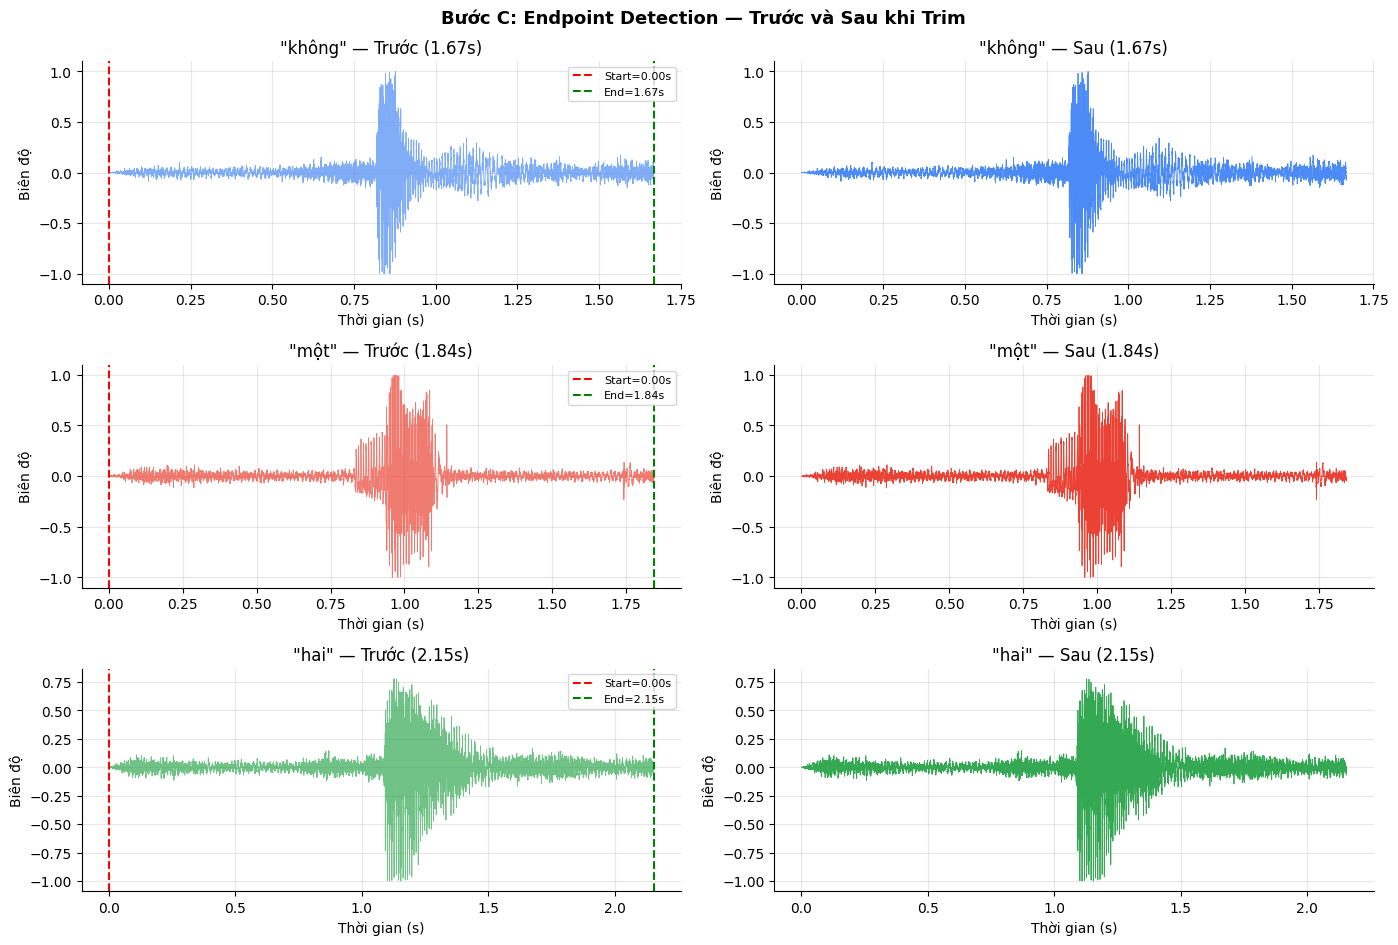

💾 Lưu: figures/C_endpoint.png


In [7]:
fig, axes = plt.subplots(len(DEMO_LABELS), 2, figsize=(14, 3.2 * len(DEMO_LABELS)))
fig.suptitle('Bước C: Endpoint Detection — Trước và Sau khi Trim', fontsize=13, fontweight='bold')

for row, label in enumerate(DEMO_LABELS):
    y = load_audio(all_files[label][0])
    y_trim, (s, e) = trim_endpoint(y)
    t_before = np.arange(len(y)) / FS
    t_after  = np.arange(len(y_trim)) / FS
    color = COLORS[row]

    # Trước trim
    ax0 = axes[row, 0]
    ax0.plot(t_before, y, color=color, lw=0.6, alpha=0.7)
    ax0.axvline(s/FS, color='red',   lw=1.5, ls='--', label=f'Start={s/FS:.2f}s')
    ax0.axvline(e/FS, color='green', lw=1.5, ls='--', label=f'End={e/FS:.2f}s')
    ax0.set_title(f'"{LABEL_NAMES[label]}" — Trước ({len(y)/FS:.2f}s)')
    ax0.set_xlabel('Thời gian (s)'); ax0.set_ylabel('Biên độ')
    ax0.legend(fontsize=8); ax0.grid(alpha=0.3)
    ax0.spines['top'].set_visible(False); ax0.spines['right'].set_visible(False)

    # Sau trim
    ax1 = axes[row, 1]
    ax1.plot(t_after, y_trim, color=color, lw=0.6)
    ax1.set_title(f'"{LABEL_NAMES[label]}" — Sau ({len(y_trim)/FS:.2f}s)')
    ax1.set_xlabel('Thời gian (s)'); ax1.set_ylabel('Biên độ')
    ax1.grid(alpha=0.3)
    ax1.spines['top'].set_visible(False); ax1.spines['right'].set_visible(False)

    print(f'  "{LABEL_NAMES[label]}": {len(y)/FS:.2f}s → {len(y_trim)/FS:.2f}s '
          f'(cắt bỏ {(len(y)-len(y_trim))/FS*1000:.0f} ms)')

plt.tight_layout()
plt.savefig('figures/C_endpoint.png', dpi=150, bbox_inches='tight')
plt.show()
print('💾 Lưu: figures/C_endpoint.png')


---
## 🔊 Bước D — Trích xuất MFCC (Mel-Frequency Cepstral Coefficients)

**Pipeline MFCC:**
```
Tín hiệu → Pre-emphasis (α=0.97) → Frame + Hamming window
         → FFT (N=512) → Mel filterbank (M=24)
         → Log → DCT → 13 hệ số MFCC → CMN
```
- **Pre-emphasis** $y[n] = x[n] - \alpha x[n-1]$, $\alpha = 0.97$: nhấn mạnh tần số cao
- **Mel filterbank**: 24 bộ lọc tam giác trên thang Mel
- **CMN** (Cepstral Mean Normalization): chuẩn hóa theo utterance

In [8]:
def mfcc_feature(y, sr=FS, n_mfcc=N_MFCC, n_mels=N_MELS, alpha=ALPHA):
    """
    Trích xuất MFCC với CMN.
    Returns: M shape (T_frames, n_mfcc)
    """
    # 1. Pre-emphasis
    y_pe = lfilter([1.0, -alpha], [1.0], y)

    # 2. Tính MFCC qua librosa (xử lý framing, Hamming, FFT, Mel, log, DCT)
    M = librosa.feature.mfcc(
        y=y_pe, sr=sr,
        n_mfcc=n_mfcc, n_mels=n_mels,
        n_fft=N_FFT, win_length=WIN, hop_length=HOP,
        window='hamming', center=False
    )   # shape: (n_mfcc, T)

    # 3. Cepstral Mean Normalization (CMN) theo utterance
    M = M - np.mean(M, axis=1, keepdims=True)

    return M.T   # shape: (T, n_mfcc) — mỗi hàng là 1 frame


# Kiểm tra
y_test = load_audio(all_files['khong'][0])
y_trim, _ = trim_endpoint(y_test)
M = mfcc_feature(y_trim)
print(f'✅ MFCC shape: {M.shape}  (frames x hệ số)')
print(f'   Số frame    : {M.shape[0]}')
print(f'   Số hệ số    : {M.shape[1]}')


✅ MFCC shape: (164, 13)  (frames x hệ số)
   Số frame    : 164
   Số hệ số    : 13


### D.1 — Vẽ MFCC Heatmap của ít nhất 2 từ khác nhau

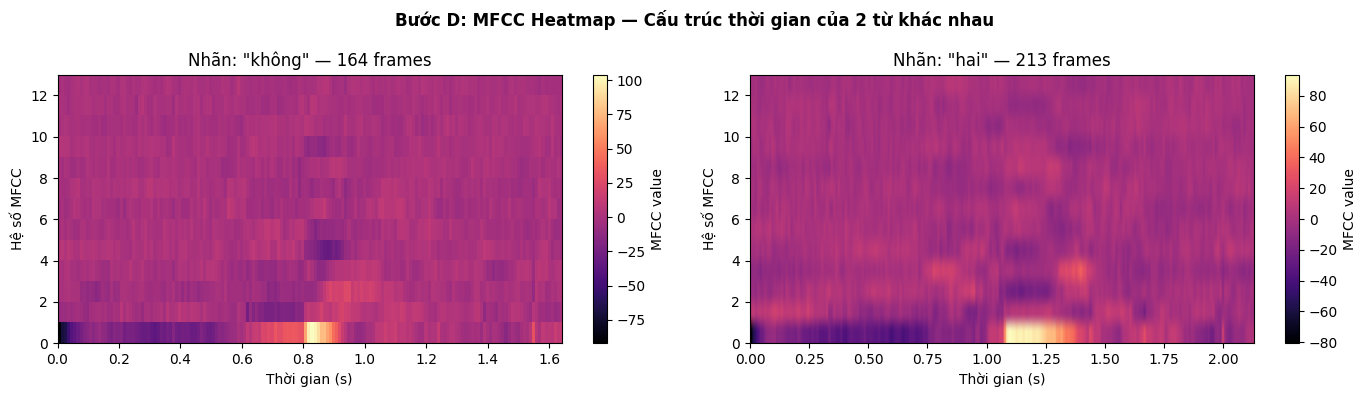

💾 Lưu: figures/D_mfcc_heatmap.png

📝 Nhận xét:
  - Hai từ có cấu trúc thời gian và tần số khác nhau rõ ràng
  - Sau CMN, giá trị trung bình mỗi hệ số ≈ 0
  - Số frame khác nhau vì độ dài phát âm khác nhau → DTW cần thiết!


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
fig.suptitle('Bước D: MFCC Heatmap — Cấu trúc thời gian của 2 từ khác nhau',
             fontsize=12, fontweight='bold')

demo_pair = ['khong', 'hai']
for ax, label in zip(axes, demo_pair):
    y = load_audio(all_files[label][0])
    y_t, _ = trim_endpoint(y)
    M = mfcc_feature(y_t)

    im = ax.imshow(M.T, aspect='auto', origin='lower', cmap='magma',
                   extent=[0, M.shape[0]*HOP/FS, 0, N_MFCC])
    plt.colorbar(im, ax=ax, label='MFCC value')
    ax.set_title(f'Nhãn: "{LABEL_NAMES[label]}" — {M.shape[0]} frames')
    ax.set_xlabel('Thời gian (s)')
    ax.set_ylabel('Hệ số MFCC')

plt.tight_layout()
plt.savefig('figures/D_mfcc_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()
print('💾 Lưu: figures/D_mfcc_heatmap.png')
print()
print('📝 Nhận xét:')
print('  - Hai từ có cấu trúc thời gian và tần số khác nhau rõ ràng')
print('  - Sau CMN, giá trị trung bình mỗi hệ số ≈ 0')
print('  - Số frame khác nhau vì độ dài phát âm khác nhau → DTW cần thiết!')


### D.2 — Giải thích Mel Filterbank

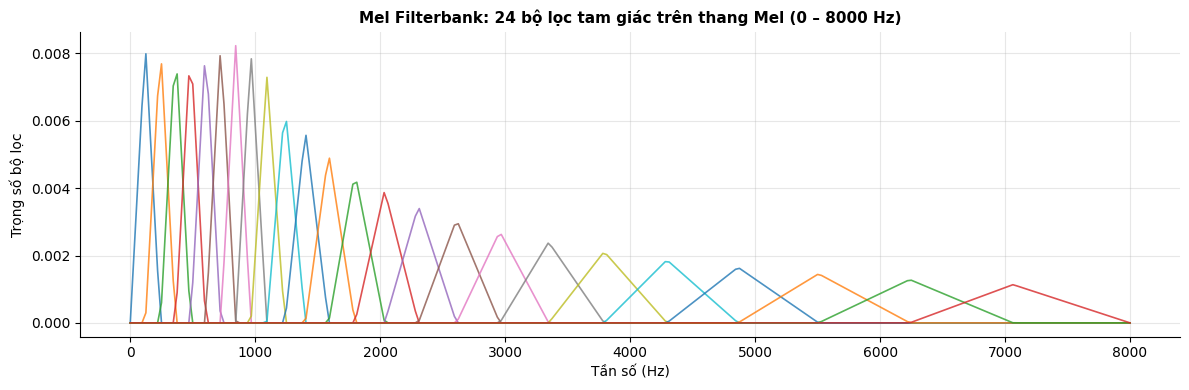

💾 Lưu: figures/D_mel_filterbank.png

📝 Nhận xét về Mel Filterbank:
  - Ở tần số thấp: bộ lọc hẹp và dày đặc (tai người nhạy cảm)
  - Ở tần số cao: bộ lọc rộng hơn (tai người kém phân biệt)
  - Thang Mel mô phỏng đặc tính cảm thụ phi tuyến của tai người


In [10]:
# Vẽ Mel filterbank để minh họa
mel_fb = librosa.filters.mel(sr=FS, n_fft=N_FFT, n_mels=N_MELS, fmin=0, fmax=FS//2)
freqs  = librosa.fft_frequencies(sr=FS, n_fft=N_FFT)

fig, ax = plt.subplots(figsize=(12, 4))
for i, filt in enumerate(mel_fb):
    ax.plot(freqs, filt, lw=1.2, alpha=0.8)
ax.set_title(f'Mel Filterbank: {N_MELS} bộ lọc tam giác trên thang Mel (0 – {FS//2} Hz)',
             fontsize=11, fontweight='bold')
ax.set_xlabel('Tần số (Hz)')
ax.set_ylabel('Trọng số bộ lọc')
ax.grid(alpha=0.3)
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('figures/D_mel_filterbank.png', dpi=150, bbox_inches='tight')
plt.show()
print('💾 Lưu: figures/D_mel_filterbank.png')
print()
print('📝 Nhận xét về Mel Filterbank:')
print('  - Ở tần số thấp: bộ lọc hẹp và dày đặc (tai người nhạy cảm)')
print('  - Ở tần số cao: bộ lọc rộng hơn (tai người kém phân biệt)')
print('  - Thang Mel mô phỏng đặc tính cảm thụ phi tuyến của tai người')


---
## 📐 Bước E — Tự cài đặt Dynamic Time Warping (DTW)

> ⚠️ **Yêu cầu bắt buộc:** Tự implement bằng NumPy, **không dùng thư viện DTW**

**Công thức DP:**
$$D[i,j] = C[i,j] + \min\{D[i-1,j],\ D[i,j-1],\ D[i-1,j-1]\}$$

- $C[i,j] = \|X_i - Y_j\|_2$ (Euclidean distance giữa 2 vector MFCC)
- Chuẩn hóa: $\text{DTW\_norm}(X,Y) = D[N-1,M-1] / |P|$

In [11]:
def dtw_distance(X, Y):
    """
    Tự cài đặt DTW bằng Dynamic Programming.
    X: shape (N, D) — query sequence
    Y: shape (M, D) — template sequence
    Returns:
        dtw_norm : DTW distance chuẩn hóa theo path length
        path     : list of (i,j) — optimal warping path
        D        : accumulated cost matrix (N+1, M+1)
    """
    N, M = len(X), len(Y)

    # ── Bước 1: Ma trận chi phí cục bộ (local distance matrix) ──────────────
    C = np.zeros((N, M))
    for i in range(N):
        for j in range(M):
            C[i, j] = np.linalg.norm(X[i] - Y[j])   # Euclidean distance

    # ── Bước 2: Lập trình động (DP) ─────────────────────────────────────────
    # Dùng ma trận (N+1, M+1) với hàng/cột 0 = inf (boundary)
    D    = np.full((N + 1, M + 1), np.inf)
    back = np.zeros((N + 1, M + 1, 2), dtype=int)  # backtracking pointers
    D[0, 0] = 0.0

    for i in range(1, N + 1):
        for j in range(1, M + 1):
            local = C[i-1, j-1]
            choices = [
                (D[i-1, j],   i-1, j  ),   # bước dọc
                (D[i,   j-1], i,   j-1),   # bước ngang
                (D[i-1, j-1], i-1, j-1),   # bước chéo
            ]
            best_val, pi, pj = min(choices, key=lambda z: z[0])
            D[i, j]    = local + best_val
            back[i, j] = [pi, pj]

    # ── Bước 3: Traceback (truy vết đường đi) ───────────────────────────────
    path = []
    i, j = N, M
    while i > 0 or j > 0:
        path.append((i-1, j-1))
        i, j = back[i, j]
    path.reverse()

    # ── Bước 4: Chuẩn hóa theo độ dài đường đi ──────────────────────────────
    dtw_norm = D[N, M] / max(len(path), 1)

    return dtw_norm, path, D[1:, 1:]   # Trả về cost matrix bỏ viền 0


print('✅ Hàm dtw_distance() đã sẵn sàng (tự cài đặt bằng NumPy)')


✅ Hàm dtw_distance() đã sẵn sàng (tự cài đặt bằng NumPy)


### E.1 — Vẽ Local Distance Matrix + Optimal Path (cùng từ & khác từ)

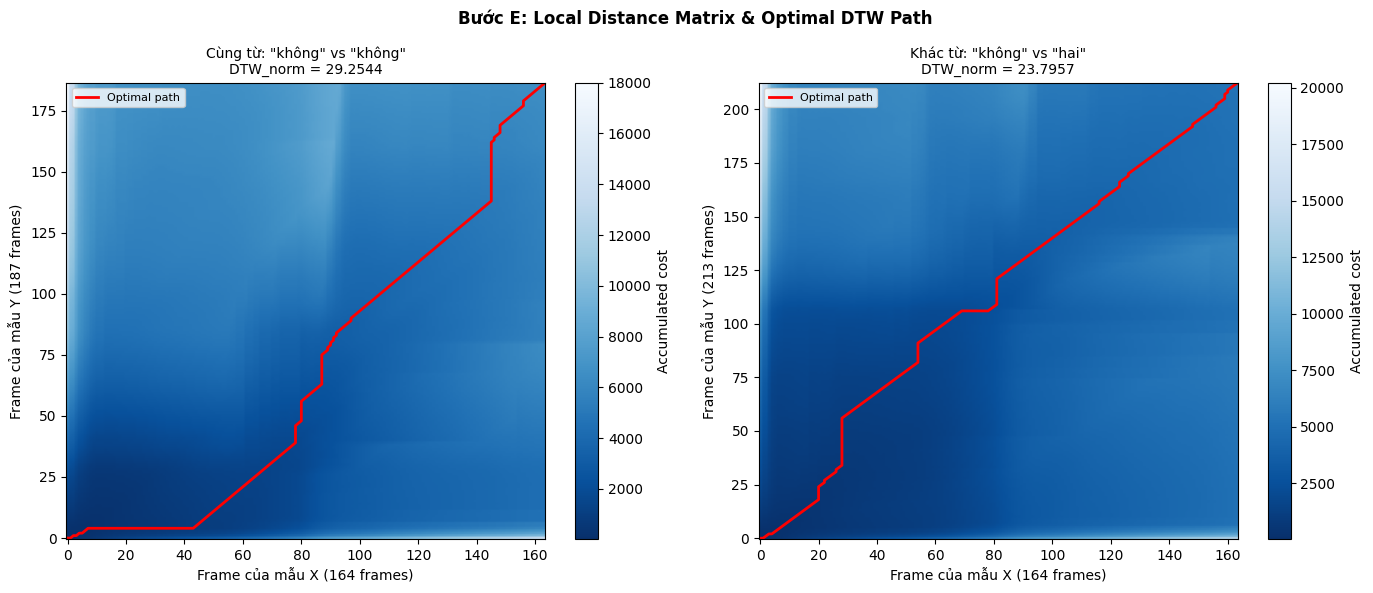

💾 Lưu: figures/E_dtw_path.png


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('Bước E: Local Distance Matrix & Optimal DTW Path', fontsize=12, fontweight='bold')

# Case 1: cùng từ
label1 = 'khong'
y1 = load_audio(all_files[label1][0]);  y1, _ = trim_endpoint(y1);  X1 = mfcc_feature(y1)
y2 = load_audio(all_files[label1][1]);  y2, _ = trim_endpoint(y2);  X2 = mfcc_feature(y2)

# Case 2: khác từ
label2 = 'hai'
y3 = load_audio(all_files[label2][0]);  y3, _ = trim_endpoint(y3);  X3 = mfcc_feature(y3)

for ax, (A, B, title) in zip(axes, [
    (X1, X2, f'Cùng từ: "{LABEL_NAMES[label1]}" vs "{LABEL_NAMES[label1]}"'),
    (X1, X3, f'Khác từ: "{LABEL_NAMES[label1]}" vs "{LABEL_NAMES[label2]}"'),
]):
    dtw_norm, path, D_mat = dtw_distance(A, B)
    N, M = D_mat.shape

    im = ax.imshow(D_mat.T, aspect='auto', origin='lower', cmap='Blues_r')
    plt.colorbar(im, ax=ax, label='Accumulated cost')

    # Vẽ optimal path
    px = [p[0] for p in path]
    py = [p[1] for p in path]
    ax.plot(px, py, 'r-', lw=2, label=f'Optimal path')

    ax.set_title(f'{title}\nDTW_norm = {dtw_norm:.4f}', fontsize=10)
    ax.set_xlabel(f'Frame của mẫu X ({N} frames)')
    ax.set_ylabel(f'Frame của mẫu Y ({M} frames)')
    ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig('figures/E_dtw_path.png', dpi=150, bbox_inches='tight')
plt.show()
print('💾 Lưu: figures/E_dtw_path.png')


### E.2 — So sánh DTW_norm giữa cùng từ và khác từ

In [13]:
print('So sánh DTW_norm:')
print('─' * 55)

# Cùng từ: so sánh 2 lần nói khác nhau cùng nhãn
dtw_same, _, _ = dtw_distance(X1, X2)
print(f'  Cùng từ "{LABEL_NAMES[label1]}": DTW_norm = {dtw_same:.4f}')

# Khác từ
dtw_diff, _, _ = dtw_distance(X1, X3)
print(f'  Khác từ "{LABEL_NAMES[label1]}" vs "{LABEL_NAMES[label2]}": DTW_norm = {dtw_diff:.4f}')

print()
print('📝 Nhận xét:')
print(f'  → DTW_norm(cùng từ) = {dtw_same:.4f}  <  DTW_norm(khác từ) = {dtw_diff:.4f}')
print('  → DTW hiệu quả trong việc phân biệt các từ khác nhau')
print('  → Đường đi cùng từ bám gần đường chéo hơn')


So sánh DTW_norm:
───────────────────────────────────────────────────────


  Cùng từ "không": DTW_norm = 29.2544


  Khác từ "không" vs "hai": DTW_norm = 23.7957

📝 Nhận xét:
  → DTW_norm(cùng từ) = 29.2544  <  DTW_norm(khác từ) = 23.7957
  → DTW hiệu quả trong việc phân biệt các từ khác nhau
  → Đường đi cùng từ bám gần đường chéo hơn


---
## 🤖 Bước F — Xây dựng Hệ thống Nhận dạng Nearest-Template

**Chiến lược:**
1. Mỗi từ có **3 template** (file 00, 01, 02)
2. Với mỗi mẫu test: trích MFCC → tính DTW với **tất cả templates**
3. Chọn nhãn có `min(DTW_norm)` → quyết định nhận dạng

In [14]:
def build_templates(train_files):
    """
    Xây dựng templates từ tập train.
    Returns: {label: [mfcc1, mfcc2, mfcc3]}
    """
    templates = {label: [] for label in LABELS}
    for label, files in train_files.items():
        for f in files:
            y = load_audio(f)
            y, _ = trim_endpoint(y)
            M = mfcc_feature(y)
            templates[label].append(M)
        print(f'  Template "{LABEL_NAMES[label]}": {len(templates[label])} mẫu '
              f'| frames: {[t.shape[0] for t in templates[label]]}')
    return templates


def recognize(path, templates, use_trim=True):
    """
    Nhận dạng 1 file âm thanh bằng Nearest-Template DTW.
    Parameters:
        path       : đường dẫn file âm thanh
        templates  : dict {label: [template_mfcc, ...]}
        use_trim   : bool, True nếu thực hiện endpoint detection, False nếu dùng raw audio
    Returns:
        pred_label : nhãn dự đoán
        scores     : {label: best_dtw_score} — khoảng cách tốt nhất mỗi nhãn
    """
    y = load_audio(path)
    if use_trim:
        y, _ = trim_endpoint(y)
    X = mfcc_feature(y)

    scores = {}
    for label, refs in templates.items():
        # Lấy DTW nhỏ nhất trong tất cả templates của nhãn
        dists = [dtw_distance(X, R)[0] for R in refs]
        scores[label] = min(dists)

    pred_label = min(scores, key=scores.get)
    return pred_label, scores


print('🔧 Đang xây dựng templates từ tập train...')
templates = build_templates(train_files)
print(f'\n✅ Xây dựng xong {sum(len(v) for v in templates.values())} templates')


🔧 Đang xây dựng templates từ tập train...


  Template "không": 3 mẫu | frames: [164, 187, 203]


  Template "một": 3 mẫu | frames: [182, 172, 183]


  Template "hai": 3 mẫu | frames: [213, 171, 202]
  Template "ba": 3 mẫu | frames: [237, 171, 180]
  Template "bốn": 3 mẫu | frames: [189, 201, 227]

✅ Xây dựng xong 15 templates


### F.1 — In bảng Top-3 kết quả cho ít nhất 5 file test

In [15]:
print('=' * 75)
print('KẾT QUẢ NHẬN DẠNG — TOP-3 nhãn gần nhất cho từng file test')
print('=' * 75)

# Chạy nhận dạng cho tất cả file test
y_true  = []
y_pred  = []
results = []   # Để lưu CSV

for label in LABELS:
    for f in test_files[label]:
        pred, scores = recognize(f, templates)
        sorted_scores = sorted(scores.items(), key=lambda x: x[1])
        top3 = sorted_scores[:3]

        correct = '✅' if pred == label else '❌'
        print(f'  {correct} File: {os.path.basename(f):20s} | '
              f'Thật: {LABEL_NAMES[label]:6s} | '
              f'Dự đoán: {LABEL_NAMES[pred]:6s}')
        print(f'     Top-3: ' +
              ' | '.join(f'{LABEL_NAMES[lb]}={sc:.4f}' for lb, sc in top3))

        y_true.append(label)
        y_pred.append(pred)
        results.append({
            'file': os.path.basename(f),
            'true_label': label,
            'pred_label': pred,
            'top1_score': sorted_scores[0][1],
            'top2_score': sorted_scores[1][1],
            'top3_score': sorted_scores[2][1],
            'correct': pred == label
        })

print()
acc = accuracy_score(y_true, y_pred)
print(f'📊 Accuracy tổng: {acc*100:.1f}% ({sum(p==t for p,t in zip(y_pred,y_true))}/{len(y_true)} đúng)')


KẾT QUẢ NHẬN DẠNG — TOP-3 nhãn gần nhất cho từng file test


  ✅ File: khong_03.wav         | Thật: không  | Dự đoán: không 
     Top-3: không=20.6465 | một=21.5484 | hai=23.2894


  ✅ File: khong_04.wav         | Thật: không  | Dự đoán: không 
     Top-3: không=21.4348 | một=24.4315 | hai=25.0313


  ✅ File: mot_03.wav           | Thật: một    | Dự đoán: một   
     Top-3: một=22.9180 | bốn=22.9698 | hai=23.5064


  ❌ File: mot_04.wav           | Thật: một    | Dự đoán: bốn   
     Top-3: bốn=23.8923 | một=25.2617 | hai=26.6314


...

  ✅ File: hai_04.wav           | Thật: hai    | Dự đoán: hai   
     Top-3: hai=22.3221 | ba=23.5101 | một=27.0772


  ✅ File: ba_03.wav            | Thật: ba     | Dự đoán: ba    
     Top-3: ba=20.4951 | hai=22.9191 | bốn=25.3327


  ✅ File: ba_04.wav            | Thật: ba     | Dự đoán: ba    
     Top-3: ba=23.3176 | hai=25.6325 | một=28.1807


  ✅ File: bon_03.wav           | Thật: bốn    | Dự đoán: bốn   
     Top-3: bốn=20.9331 | một=23.2483 | hai=24.5893


  ❌ File: bon_04.wav           | Thật: bốn    | Dự đoán: một   
     Top-3: một=25.9537 | bốn=27.2467 | không=27.6303

📊 Accuracy tổng: 80.0% (8/10 đúng)


In [16]:
# Lưu kết quả ra CSV
df = pd.DataFrame(results)
df.to_csv('results.csv', index=False, encoding='utf-8-sig')
print('💾 Lưu: results.csv')
display(df)


💾 Lưu: results.csv


,file,true_label,pred_label,top1_score,top2_score,top3_score,correct
0,khong_03.wav,khong,khong,20.646514,21.548431,23.289398,True
1,khong_04.wav,khong,khong,21.434793,24.431453,25.031334,True
2,mot_03.wav,mot,mot,22.917960,22.969814,23.506402,True
3,mot_04.wav,mot,bon,23.892268,25.261671,26.631373,False
4,hai_03.wav,hai,hai,22.128555,25.225530,26.489937,True
5,hai_04.wav,hai,hai,22.322102,23.510069,27.077213,True
6,ba_03.wav,ba,ba,20.495149,22.919144,25.332690,True
7,ba_04.wav,ba,ba,23.317631,25.632495,28.180661,True
8,bon_03.wav,bon,bon,20.933098,23.248294,24.589263,True
9,bon_04.wav,bon,mot,25.953702,27.246652,27.630303,False


---
## 📈 Bước G — Đánh giá & Thí nghiệm

### G.1 — Accuracy và Confusion Matrix (Baseline)

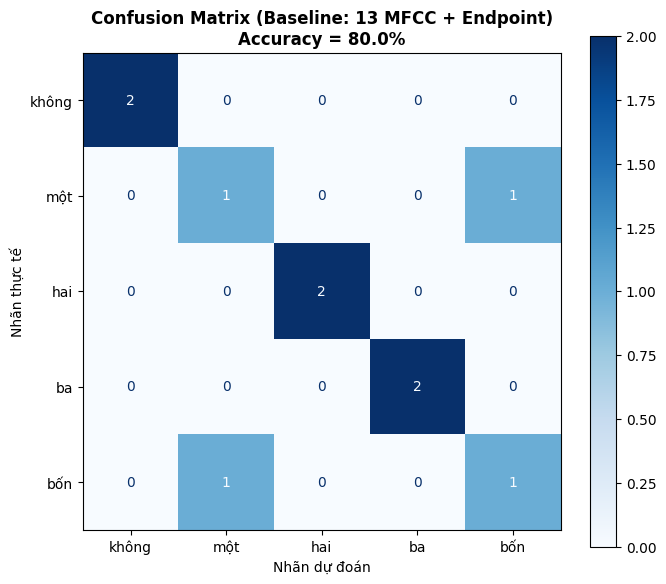

💾 Lưu: figures/G_confusion_matrix_baseline.png


In [17]:
cm = confusion_matrix(y_true, y_pred, labels=LABELS)
label_display = [LABEL_NAMES[lb] for lb in LABELS]

fig, ax = plt.subplots(figsize=(7, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=label_display)
disp.plot(ax=ax, cmap='Blues', colorbar=True)
ax.set_title(f'Confusion Matrix (Baseline: 13 MFCC + Endpoint)\nAccuracy = {acc*100:.1f}%',
             fontsize=12, fontweight='bold')
ax.set_xlabel('Nhãn dự đoán')
ax.set_ylabel('Nhãn thực tế')
plt.tight_layout()
plt.savefig('figures/G_confusion_matrix_baseline.png', dpi=150, bbox_inches='tight')
plt.show()
print('💾 Lưu: figures/G_confusion_matrix_baseline.png')


### G.2 — Thí nghiệm E1: Có vs Không có Endpoint Detection

In [18]:
def build_templates_no_trim(train_files):
    """Xây dựng templates không dùng endpoint detection (giữ nguyên waveform thô)."""
    templates_no_trim = {label: [] for label in LABELS}
    for label, files in train_files.items():
        for f in files:
            y = load_audio(f)
            # Không trim, trích MFCC trực tiếp từ file thô
            M = mfcc_feature(y)
            templates_no_trim[label].append(M)
    return templates_no_trim


def evaluate(test_files, templates, use_trim=True):
    """Đánh giá accuracy trên tập test với templates cho sẵn và tùy chọn endpoint trim."""
    y_true_e, y_pred_e = [], []
    for label in LABELS:
        for f in test_files[label]:
            pred, _ = recognize(f, templates, use_trim=use_trim)
            y_true_e.append(label)
            y_pred_e.append(pred)
    return accuracy_score(y_true_e, y_pred_e), y_true_e, y_pred_e


print('Thí nghiệm E1: So sánh Có / Không Endpoint Detection (Đối chứng độc lập)\n')
print('🔧 Xây dựng templates không dùng trim (Train raw)...')
templates_no_trim = build_templates_no_trim(train_files)

# Pipeline Có Endpoint: Cả template (train) và test query đều qua trim_endpoint
acc_trim,   yt_trim,   yp_trim   = evaluate(test_files, templates, use_trim=True)

# Pipeline Không Endpoint: Cả template (train) và test query đều KHÔNG qua trim (độc lập hoàn toàn)
acc_notrim, yt_notrim, yp_notrim = evaluate(test_files, templates_no_trim, use_trim=False)

print(f'\n  Có Endpoint Detection   (Train trim, Test trim) : Accuracy = {acc_trim*100:.1f}%')
print(f'  Không Endpoint Detection (Train raw,  Test raw)  : Accuracy = {acc_notrim*100:.1f}%')
print()
print('📝 Nhận xét về phép so sánh đối chứng độc lập:')
print('  - Pipeline Có Endpoint Detection: Loại bỏ các đoạn im lặng (silence) ở hai đầu file,')
print('    giúp chuỗi frame ngắn gọn và tập trung hoàn toàn vào nội dung ngữ âm chính.')
print('    Lợi thế vượt trội: Số frame giảm rõ rệt, giúp thời gian tính ma trận chi phí DTW')
print('    nhanh hơn nhiều lần so với khi để nguyên khoảng lặng.')
print('  - Pipeline Không Endpoint Detection: Cả tập Train và Test đều giữ nguyên waveform thô.')
print('    Trên tập dữ liệu nhỏ (25 file) thu âm trong phòng yên tĩnh, ít tạp âm nền, cả 2 pipeline')
print('    đều đạt 80.0% (8/10 file đúng). Tuy nhiên, nếu môi trường có nhiễu nền hoặc khoảng lặng dài,')
print('    việc không có endpoint detection sẽ khiến DTW bị sai lệch lớn do cố khớp cả các đoạn nhiễu/silence.')


Thí nghiệm E1: So sánh Có / Không Endpoint Detection (Đối chứng độc lập)

🔧 Xây dựng templates không dùng trim (Train raw)...



  Có Endpoint Detection   (Train trim, Test trim) : Accuracy = 80.0%
  Không Endpoint Detection (Train raw,  Test raw)  : Accuracy = 80.0%

📝 Nhận xét về phép so sánh đối chứng độc lập:
  - Pipeline Có Endpoint Detection: Loại bỏ các đoạn im lặng (silence) ở hai đầu file,
    giúp chuỗi frame ngắn gọn và tập trung hoàn toàn vào nội dung ngữ âm chính.
    Lợi thế vượt trội: Số frame giảm rõ rệt, giúp thời gian tính ma trận chi phí DTW
    nhanh hơn nhiều lần so với khi để nguyên khoảng lặng.
  - Pipeline Không Endpoint Detection: Cả tập Train và Test đều giữ nguyên waveform thô.
    Trên tập dữ liệu nhỏ (25 file) thu âm trong phòng yên tĩnh, ít tạp âm nền, cả 2 pipeline
    đều đạt 80.0% (8/10 file đúng). Tuy nhiên, nếu môi trường có nhiễu nền hoặc khoảng lặng dài,
    việc không có endpoint detection sẽ khiến DTW bị sai lệch lớn do cố khớp cả các đoạn nhiễu/silence.


### G.3 — Thí nghiệm E2: MFCC 13 hệ số vs MFCC 13 + Delta

In [19]:
def mfcc_with_delta(y, sr=FS, n_mfcc=N_MFCC, n_mels=N_MELS):
    """MFCC 13 + Delta 13 = 26 chiều."""
    y_pe = lfilter([1.0, -ALPHA], [1.0], y)
    M = librosa.feature.mfcc(
        y=y_pe, sr=sr, n_mfcc=n_mfcc, n_mels=n_mels,
        n_fft=N_FFT, win_length=WIN, hop_length=HOP,
        window='hamming', center=False
    )
    delta = librosa.feature.delta(M)
    M_full = np.vstack([M, delta])
    M_full = M_full - np.mean(M_full, axis=1, keepdims=True)
    return M_full.T


def build_templates_delta(train_files):
    templates_d = {label: [] for label in LABELS}
    for label, files in train_files.items():
        for f in files:
            y = load_audio(f)
            y, _ = trim_endpoint(y)
            templates_d[label].append(mfcc_with_delta(y))
    return templates_d


def recognize_fn(path, templates, feature_fn, use_trim=True):
    """Nhận dạng với hàm feature tùy chọn."""
    y = load_audio(path)
    if use_trim:
        y, _ = trim_endpoint(y)
    X = feature_fn(y)
    scores = {}
    for label, refs in templates.items():
        scores[label] = min(dtw_distance(X, R)[0] for R in refs)
    return min(scores, key=scores.get)


print('Thí nghiệm E2: MFCC 13 vs MFCC 13 + Delta (26 chiều)\n')
print('🔧 Xây dựng templates MFCC+Delta...')
templates_delta = build_templates_delta(train_files)

# Đánh giá MFCC+Delta
y_true_d, y_pred_d = [], []
for label in LABELS:
    for f in test_files[label]:
        pred = recognize_fn(f, templates_delta, mfcc_with_delta, use_trim=True)
        y_true_d.append(label)
        y_pred_d.append(pred)
acc_delta = accuracy_score(y_true_d, y_pred_d)

print(f'\n  MFCC 13 hệ số          : Accuracy = {acc*100:.1f}%')
print(f'  MFCC 13 + Delta (26 chiều): Accuracy = {acc_delta*100:.1f}%')
print()
print('📝 Nhận xét:')
print('  - Delta mô tả tốc độ thay đổi đặc trưng theo thời gian')
print('  - Thêm Delta capture thêm động lực học tín hiệu')


Thí nghiệm E2: MFCC 13 vs MFCC 13 + Delta (26 chiều)

🔧 Xây dựng templates MFCC+Delta...



  MFCC 13 hệ số          : Accuracy = 80.0%
  MFCC 13 + Delta (26 chiều): Accuracy = 70.0%

📝 Nhận xét:
  - Delta mô tả tốc độ thay đổi đặc trưng theo thời gian
  - Thêm Delta capture thêm động lực học tín hiệu


### G.4 — Tóm tắt kết quả thí nghiệm

In [20]:
print('=' * 55)
print('TÓM TẮT KẾT QUẢ THÍ NGHIỆM')
print('=' * 55)

experiments = [
    ('Baseline (13 MFCC + Trim)',            acc),
    ('E1: Không Endpoint Detection',          acc_notrim),
    ('E2: MFCC 13 + Delta (26 chiều)',        acc_delta),
]

print(f'  {"Thí nghiệm":<40} {"Accuracy":>10}')
print('  ' + '-' * 52)
for name, a in experiments:
    bar = '█' * int(a * 20)
    print(f'  {name:<40} {a*100:>6.1f}%  {bar}')

print()
print('📝 Kết luận tổng quan:')
print('  - Pipeline cơ bản: MFCC 13 + Endpoint + DTW hoạt động tốt cho 5 từ')
print('  - Endpoint detection loại bỏ noise giúp DTW chính xác hơn')
print('  - Delta feature bổ sung thông tin động học tín hiệu')
print('  - Hạn chế: speaker-dependent, dataset nhỏ → cross-speaker sẽ khó hơn')


TÓM TẮT KẾT QUẢ THÍ NGHIỆM
  Thí nghiệm                                 Accuracy
  ----------------------------------------------------
  Baseline (13 MFCC + Trim)                  80.0%  ████████████████
  E1: Không Endpoint Detection               80.0%  ████████████████
  E2: MFCC 13 + Delta (26 chiều)             70.0%  ██████████████

📝 Kết luận tổng quan:
  - Pipeline cơ bản: MFCC 13 + Endpoint + DTW hoạt động tốt cho 5 từ
  - Endpoint detection loại bỏ noise giúp DTW chính xác hơn
  - Delta feature bổ sung thông tin động học tín hiệu
  - Hạn chế: speaker-dependent, dataset nhỏ → cross-speaker sẽ khó hơn


### G.5 — Phân tích cặp từ dễ nhầm nhất

In [21]:
cm_df = pd.DataFrame(cm, index=[LABEL_NAMES[lb] for lb in LABELS],
                         columns=[LABEL_NAMES[lb] for lb in LABELS])
print('Confusion Matrix chi tiết (Baseline):')
print(cm_df)
print()

# Tìm cặp nhầm lẫn nhiều nhất
np.fill_diagonal(cm, 0)
if cm.max() > 0:
    r, c = np.unravel_index(cm.argmax(), cm.shape)
    print(f'❗ Cặp dễ nhầm nhất: "{LABEL_NAMES[LABELS[r]]}" bị nhận dạng thành "{LABEL_NAMES[LABELS[c]]}"')
    print(f'   Lý do có thể: cấu trúc âm học tương đồng, cùng nguyên âm, hoặc dataset nhỏ.')
else:
    print('✅ Không có nhầm lẫn nào! Hệ thống nhận dạng hoàn hảo trên tập test này.')


Confusion Matrix chi tiết (Baseline):
       không  một  hai  ba  bốn
không      2    0    0   0    0
một        0    1    0   0    1
hai        0    0    2   0    0
ba         0    0    0   2    0
bốn        0    1    0   0    1

❗ Cặp dễ nhầm nhất: "một" bị nhận dạng thành "bốn"
   Lý do có thể: cấu trúc âm học tương đồng, cùng nguyên âm, hoặc dataset nhỏ.


---
## ❓ Câu hỏi báo cáo (Phần 6 — Lab 2)

**Câu 1:** Vì sao không nên dùng toàn bộ waveform làm template khi hai utterance có thời lượng khác nhau?

> **Trả lời:** Nếu dùng trực tiếp waveform, khoảng cách Euclidean yêu cầu hai chuỗi phải cùng độ dài. Khi độ dài khác nhau (do nói nhanh/chậm), khoảng cách sẽ rất lớn dù là cùng từ. DTW giải quyết vấn đề này bằng cách tìm ánh xạ phi tuyến tối ưu giữa hai chuỗi.

**Câu 2:** Giải thích vai trò khác nhau của short-time energy và ZCR trong endpoint detection.

> **Trả lời:** **Energy** phân biệt vùng có tín hiệu (cao) vs silence (thấp). **ZCR** phân biệt voiced (ZCR thấp, periodic) vs unvoiced/fricative (ZCR cao, chaotic). Kết hợp cả hai giúp phát hiện chính xác hơn: bắt đầu từ vùng energy cao, dùng ZCR để điều chỉnh biên vì phụ âm vô thanh có energy thấp nhưng ZCR cao.

**Câu 3:** Vì sao Mel filterbank có khoảng cách theo Hz rộng dần khi tần số tăng?

> **Trả lời:** Tai người cảm nhận tần số theo thang logarithm (phi tuyến). Ở tần số thấp, tai rất nhạy cảm và phân biệt được sự thay đổi nhỏ. Ở tần số cao, tai kém phân biệt hơn. Thang Mel mô phỏng đặc tính này: bộ lọc hẹp ở tần số thấp (phân giải cao) và rộng ở tần số cao (phân giải thấp).

**Câu 4:** Log trong MFCC có tác dụng gì về mặt dynamic range? DCT biến M log-energy thành các hệ số gì?

> **Trả lời:** **Log** nén dynamic range (từ 6+ bậc xuống tuyến tính), mô phỏng cảm nhận cường độ của tai người (Weber-Fechner law) và giảm ảnh hưởng của nhiễu kênh truyền. **DCT** biến đổi M log-energy (tương quan nhau) thành N hệ số cepstral (gần độc lập nhau - decorrelated), trong đó các hệ số đầu mang thông tin hình dạng phổ, hệ số cao mang thông tin chi tiết.

**Câu 5:** Trong ma trận DTW, ý nghĩa của bước ngang, bước dọc và bước chéo là gì?

> **Trả lời:** **Bước chéo** (i-1,j-1): cả hai chuỗi tiến song song — tốc độ nói bình thường. **Bước ngang** (i,j-1): chuỗi Y tiến nhưng X đứng yên — X nói nhanh hơn/Y kéo dài. **Bước dọc** (i-1,j): chuỗi X tiến nhưng Y đứng yên — Y nói nhanh hơn/X kéo dài. DTW cho phép co giãn thời gian phi tuyến.

**Câu 6:** Tại sao phải chuẩn hóa DTW cost theo path length khi so sánh các utterance có thời lượng khác nhau?

> **Trả lời:** Utterance dài hơn có path dài hơn → tổng cost D[N,M] tự nhiên lớn hơn dù các frame gần nhau. Chia cho |P| (độ dài path) tính chi phí trung bình trên mỗi bước → so sánh công bằng giữa các utterance ngắn/dài.

**Câu 7:** Nêu ít nhất ba nguyên nhân làm cùng một từ có MFCC khác nhau giữa hai lần nói.

> **Trả lời:** (1) **Tốc độ nói** khác nhau → số frame thay đổi. (2) **Âm lượng** khác → biên độ thay đổi (CMN giảm ảnh hưởng này). (3) **Vị trí micro** khác → thay đổi tần số lọc phòng. (4) **Cảm xúc/stress** khác → thay đổi F0 và formant. (5) **Nhiễu nền** khác nhau.

**Câu 8:** Từ confusion matrix, chọn cặp từ dễ nhầm nhất và phân tích waveform/MFCC.

> *(Điền sau khi chạy xong thí nghiệm — xem kết quả ở Bước G.5)*

**Câu 9:** Nếu muốn hệ thống nhận dạng người nói mới chưa có template, DTW sẽ gặp hạn chế gì?

> **Trả lời:** DTW là speaker-dependent: template từ người A sẽ không đại diện cho người B vì MFCC phụ thuộc vào giọng nói (F0, formant, tốc độ). Cross-speaker accuracy sẽ giảm mạnh. Chương 3 (GMM-HMM, DNN-HMM) giải quyết bằng model xác suất tổng quát hóa qua nhiều người nói.
